# Anatomy of run 53's converged network: how 62 rows, 60 units and 2 neurons implement the depth-5 tree

Run 53 (notebook 2, section 8) is the anchor design trained in two phases on 10M points: 62-60-2, every first-layer row on an ODT
normal at the end, test error 0.13%. Since every first-layer row sits on a normal, the first layer is a bank of 62 features
`f_r(x) = ||w_r|| relu(+-a_n(x))` with `a_n = u_n . x`, and every second-layer unit is a weighted sum of these features through a ReLU.
This notebook reads the weights in that basis and asks how the network computes the label `y = sign(a_m(x))` of the level-4 node `m`
the point reaches.

Sections: 1 the first layer as a feature bank; 2 the second layer in the feature basis (vetoes and backgrounds); 3 the 32 level-3 units
as leaf detectors; 4 the 28 lower-level units; 5 the readout: contributions, ablations, the third layer, and the decision near the
boundary. Findings are summarised at the end of each section.


In [31]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pickle
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import NODE_LEVEL, node_ancestors, HIERARCHY_TARGETS
from layer_lenses.init_sweep import SweepRunSpec, build_data, load_tree
np.set_printoptions(linewidth=200, precision=2, suppress=True); pd.set_option("display.width", 220)
RUN = Path("../results/designed_init/hd2_run53_phased2_cue1_10M"); tree = load_tree(RUN / "tree.npz"); U = tree.w_list
z = np.load(RUN / "replay/weights.npz"); 
EPOCH = 100
W1, W2, W3, Wo = (z[k][EPOCH].astype(np.float64) for k in ["w__hidden_layers.0.weight", "w__hidden_layers.1.weight", "w__hidden_layers.2.weight", "w__output_layer.weight"])
meta = pickle.load(open(RUN / "replay/meta.pkl", "rb")); ups = np.array(meta["design"]["unit_path_sign"]); ubs = np.array(meta["design"]["unit_block_sign"]); unode = np.array(meta["design"]["unit_node"])
x, y = build_data(SweepRunSpec(tree_seed=5178, data_seed=999_777, init_seed=0, batch_size=1, n_train=100_000), tree); A = x @ U.T      # a_n(x) for the 31 normals
# first-layer rows as (node, pole) features; forward pass
nrm = np.linalg.norm(W1, axis=1); Cos = W1 / nrm[:, None] @ U.T; top = np.abs(Cos).argmax(1); pole = np.sign(Cos[np.arange(62), top]).astype(int); cos = np.abs(Cos).max(1)
rname = np.array([f"{'+' if pole[r] > 0 else '-'}u{top[r]}" for r in range(62)]); Weff = W2 * nrm[None, :]                   # unit weights on the unit-norm features relu(pole a_node)
F = np.maximum(pole[None, :] * A[:, top], 0); h1 = np.maximum(x @ W1.T, 0); h2 = np.maximum(h1 @ W2.T, 0); S = h2 @ W3.T; logit = np.maximum(S, 0) @ Wo.ravel()
readout = np.where(ups > 0, W3[0] * Wo[0, 0], W3[1] * Wo[0, 1]); contrib = h2 * readout[None, :]
def reach4(A):
    node = np.zeros(len(A), int)
    for lvl in range(4): node = 2 * node + 1 + (A[np.arange(len(A)), node] > 0)
    return node
m_reached = reach4(A); assert np.array_equal(np.sign(A[np.arange(len(A)), m_reached]), y)
utype = np.array([f"({'+' if b > 0 else '-'}B,{'+' if s > 0 else '-'})" for b, s in zip(ubs, ups)])
print(f"test error {((logit >= 0) != (y > 0)).mean():.5f} on {len(y)} points; logit rms {np.sqrt((logit ** 2).mean()):.1f}; output weights {Wo.ravel().round(2)}")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
test error 0.03802 on 100000 points; logit rms 9.9; output weights [ 18.03 -18.04]


## 1. The first layer is a bank of 62 one-sided features on the tree's normals

In [32]:
rows = pd.DataFrame({"row": range(62), "kind": ["probe"] * 30 + ["cue"] * 32, "node": top, "pole": pole, "level": NODE_LEVEL[top], "norm": nrm, "cos": cos, "off_span_frac": np.linalg.norm(W1 - (W1 @ U.T) @ U, axis=1) / nrm})
print(rows.groupby(["kind", "level"]).agg(n=("row", "size"), norm_mean=("norm", "mean"), norm_min=("norm", "min"), norm_max=("norm", "max"), cos_min=("cos", "min"), off_span_max=("off_span_frac", "max")).round(3))
print("every (node, pole) pair has exactly one row:", sorted(zip(top, pole)) == sorted((n, p) for n in range(31) for p in (1, -1)))
print("feature approximation |h1 - norm * relu(pole a_node)| max over points / rows:", np.abs(h1 - F * nrm).max().round(3), "(relative to row norm x typical |a| ~", (nrm.mean() * 0.08).round(2), ")")

              n  norm_mean  norm_min  norm_max  cos_min  off_span_max
kind  level                                                          
cue   4      32      1.414     1.414     1.414    0.459         0.000
probe 0       2      8.604     8.547     8.661    1.000         0.004
      1       4      6.315     6.285     6.343    0.997         0.005
      2       8      4.821     4.807     4.853    0.997         0.007
      3      16      3.689     3.677     3.706    0.997         0.010
every (node, pole) pair has exactly one row: True
feature approximation |h1 - norm * relu(pole a_node)| max over points / rows: 0.548 (relative to row norm x typical |a| ~ 0.24 )


**Findings.** All 62 rows sit on a normal (cosine at least 0.999, off-span part at most 0.5%), one row per (node, pole): 30 probes
on +-u_0..u_14, 32 cues on +-u_15..u_30. So the first layer computes `f_(n,+)(x) = ||w|| relu(a_n)` and `f_(n,-)(x) = ||w|| relu(-a_n)`
for every node, with norms that grow toward the root: 12.8 at level 0, 9.0 / 7.0 / 5.7 at levels 1-3, 1.6 for the cues. The ratio of
the two halves of a coordinate is what the second layer will use: `f_(n,+) - f_(n,-) = ||w|| a_n`.


## 2. The second layer in the feature basis: vetoes and backgrounds

`Weff[u, r] = W2[u, r] ||w_r||` is unit `u`'s weight on the unit-norm feature `relu(pole a_node)`. The heatmap orders units by node
(4 per node, nodes by level) and features by node and pole.

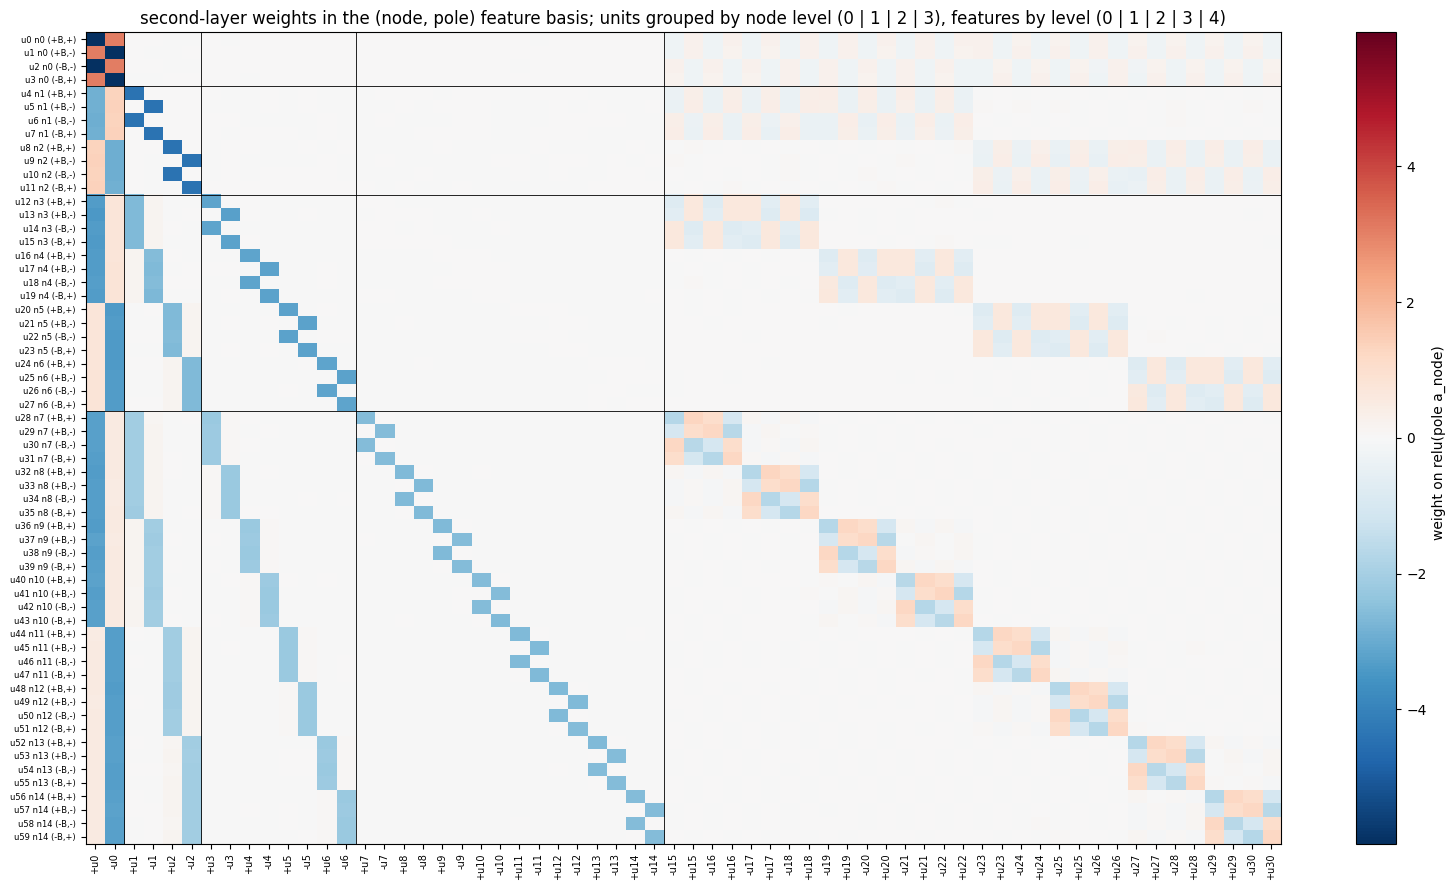

 unit  node  level   type  readout                                                              vetoes (weight < -1)  n positive weights  sum of positive weights largest positive
    0     0      0 (+B,+)     23.7                                                                     [(+u0, -5.9)]                  41                     7.25         -u0 3.06
    1     0      0 (+B,-)    -23.0                                                                     [(-u0, -6.0)]                  43                     7.28         +u0 3.07
    2     0      0 (-B,-)    -23.7                                                                     [(+u0, -6.0)]                  42                     7.27         -u0 3.07
    3     0      0 (-B,+)     22.9                                                                     [(-u0, -6.0)]                  42                     7.29         +u0 3.06
    4     1      1 (+B,+)     30.5                                                        [(+u1, -4.4), (

In [59]:
order_r = np.arange(62);
EPOCH = 30
W1, W2, W3, Wo = (z[k][EPOCH].astype(np.float64) for k in ["w__hidden_layers.0.weight", "w__hidden_layers.1.weight", "w__hidden_layers.2.weight", "w__output_layer.weight"])
nrm = np.linalg.norm(W1, axis=1)
Weff = W2 * nrm[None, :]   
# order_r = np.lexsort((-pole, top)); 
fig, ax = plt.subplots(figsize=(16, 9))
im = ax.imshow(Weff[:, order_r], cmap="RdBu_r", vmin=-np.abs(Weff).max(), vmax=np.abs(Weff).max(), aspect="auto"); plt.colorbar(im, ax=ax, label="weight on relu(pole a_node)  ")
ax.set_xticks(range(62)); ax.set_xticklabels(rname[order_r], rotation=90, fontsize=7); ax.set_yticks(range(60)); ax.set_yticklabels([f"u{u} n{unode[u]} {utype[u]}" for u in range(60)], fontsize=6)
for k in (4, 12, 28): ax.axhline(k - 0.5, color="k", lw=0.6)
for k in (2, 6, 14, 30): ax.axvline(k - 0.5, color="k", lw=0.6)
ax.set_title("second-layer weights in the (node, pole) feature basis; units grouped by node level (0 | 1 | 2 | 3), features by level (0 | 1 | 2 | 3 | 4)"); plt.tight_layout(); plt.show()
# per unit: large negative weights (vetoes) and the sum of positive weights (background)
rec = []
for u in range(60):
    w = Weff[u]; vet = [(rname[r], round(float(w[r]), 1)) for r in np.argsort(w) if w[r] < -1.0]; posw = w[w > 0]
    rec.append({"unit": u, "node": unode[u], "level": NODE_LEVEL[unode[u]], "type": utype[u], "readout": round(float(readout[u]), 1), "vetoes (weight < -1)": vet, "n positive weights": int((w > 0).sum()), "sum of positive weights": round(float(posw.sum()), 2), "largest positive": f"{rname[np.argmax(w)]} {w.max():.2f}"})
recipes = pd.DataFrame(rec); print(recipes.to_string(index=False, max_colwidth=110))

**Findings.** Every unit has the same two-part structure: a few **vetoes**, large negative weights (20-55) on the *wrong-side* feature
of each node on a path, and a **background**, dozens of small positive weights (0.03-0.8 each, 30-60 of them, summing to 2-10) spread
over the other features (the sums range from 1 to 9; the level-0 unit 3 and the level-1 units carry the largest backgrounds). The vetoes
are the design's probe weights (-1 at init) grown by a factor 20-50; the cue blocks, which at init were the only in-span signal, have
turned into a 4-unit veto on one cue (level-3 units) or dissolved into the background. A unit's pre-activation is `b_u(x) - sum of
vetoes`, so the unit is a ReLU of a small, slowly varying positive quantity from which the vetoes subtract a large multiple of the
wrong-side coordinates: it is active only where every vetoed coordinate is on the right side, and there it outputs the background.


## 3. The 32 level-3 units are the leaf detectors: one per (level-4 node, label sign)

A level-3 unit of node `j` vetoes the wrong side of `u_0`, of `j`'s level-1 and level-2 ancestors and of `u_j` itself, which confines
it to the region of one child `m` of `j` (a level-4 node), and it vetoes one cue of `m`, which confines it further to one sign of `a_m`,
i.e. to one label. Its readout has the sign of that label.

In [4]:
lvl3 = [u for u in range(60) if NODE_LEVEL[unode[u]] == 3]; rows3 = []
for u in lvl3:
    w = Weff[u]; vet_rows = [r for r in np.argsort(w) if w[r] < -1.0]; cue_r = [r for r in vet_rows if top[r] >= 15][0]; m, q = int(top[cue_r]), int(pole[cue_r]); label = -q
    region = m_reached == m; right = region & (np.sign(A[:, m]) == label); wrong = region & (np.sign(A[:, m]) == -label)
    b = F @ np.maximum(w, 0); v = F @ np.maximum(-w, 0)
    rows3.append({"unit": u, "node j": unode[u], "type": utype[u], "region m": m, "label served": label, "readout": round(float(readout[u]), 1), "vetoes on path (root..j)": [round(float(w[r]), 0) for r in vet_rows if top[r] < 15], "cue veto": f"{rname[cue_r]} {w[cue_r]:.1f}",
                  "active: region & right sign": round(float((h2[right, u] > 0).mean()), 3), "region & wrong sign": round(float((h2[wrong, u] > 0).mean()), 3), "off region": round(float((h2[~region, u] > 0).mean()), 4),
                  "output on region & right sign: mean": round(float(h2[right, u].mean()), 3), "= background b: corr": round(float(np.corrcoef(h2[right, u], b[right])[0, 1]), 3), "b mean / cv": f"{b.mean():.2f} / {b.std() / b.mean():.2f}"})
t3 = pd.DataFrame(rows3); print(t3.to_string(index=False))
print("\neach (level-4 node, label) served by exactly one level-3 unit:", sorted(zip(t3["region m"], t3["label served"])) == sorted((m, s) for m in range(15, 31) for s in (1, -1)), "| readout sign = label served:", bool((np.sign(t3.readout) == t3["label served"]).all()))
print("veto size by level of the vetoed node (mean over level-3 units): " + ", ".join(f"level {l}: {np.mean([abs(Weff[u, r]) for u in lvl3 for r in range(62) if Weff[u, r] < -1 and NODE_LEVEL[top[r]] == l]):.0f}" for l in range(5)))

 unit  node j   type  region m  label served  readout     vetoes on path (root..j)  cue veto  active: region & right sign  region & wrong sign  off region  output on region & right sign: mean  = background b: corr b mean / cv
   28       7 (+B,+)        15             1     70.1 [-53.0, -36.0, -30.0, -30.0] -u15 -4.3                        1.000                0.087      0.0006                                0.070                 0.953 0.05 / 0.54
   29       7 (+B,-)        16            -1    -74.6 [-55.0, -36.0, -30.0, -29.0] +u16 -4.2                        1.000                0.097      0.0009                                0.071                 0.947 0.05 / 0.55
   30       7 (-B,-)        15            -1    -79.9 [-54.0, -36.0, -30.0, -30.0] +u15 -4.0                        1.000                0.091      0.0008                                0.072                 0.935 0.05 / 0.53
   31       7 (-B,+)        16             1     76.7 [-54.0, -36.0, -30.0, -30.0] -u16 -3.6    

**Findings.** The 32 level-3 units are exactly the 32 (level-4 node, label) detectors: every pair is served once, the unit is active
on essentially all points of its region with the right label sign, on about 9% of the points with the wrong sign (those with |a_m|
small, where the 4-unit cue veto has not yet overcome the background), and on 0.06% of the points outside its region. The vetoes
grow toward the root (about 54 on the root's wrong side, 36 at level 1, 30 at levels 2 and 3, 4 on the cue), the same order as the
row norms, so a point a fixed distance on the wrong side of a deep split is vetoed as surely as one far on the wrong side of the root.
On its (region, sign) set the unit outputs its background `b_u(x)` (correlation 0.95 between the two), a sum of small positive
weights over most features with mean 0.05 and coefficient of variation 0.55 across the sphere, so the output is 0.07 on average on
the set. So the unit is a soft indicator `1[x reaches m and sign(a_m) = s]` of height `b_u(x)`, and its readout (+70 to +82 for s = +,
-68 to -82 for s = -) turns it into a contribution of about +-5 to the logit with the sign of the label.


## 4. The 28 lower-level units: coarse region detectors with weak label information

In [5]:
rows_lo = []
for u in [u for u in range(60) if NODE_LEVEL[unode[u]] < 3]:
    w = Weff[u]; vet_rows = [r for r in np.argsort(w) if w[r] < -1.0]
    region = np.ones(len(A), bool)
    for r in vet_rows: region &= (pole[r] * A[:, top[r]] <= 0)                                    # the region the vetoes leave: right side of every vetoed node
    depth = max(NODE_LEVEL[top[r]] for r in vet_rows) + 1
    rows_lo.append({"unit": u, "node": unode[u], "level": NODE_LEVEL[unode[u]], "type": utype[u], "readout": round(float(readout[u]), 1), "vetoes": [rname[r] for r in vet_rows], "region: subtree of a node at level": depth, "region fraction": round(float(region.mean()), 3),
                    "active on region": round(float((h2[region, u] > 0).mean()), 3), "active off region": round(float((h2[~region, u] > 0).mean()), 4), "mean output on region": round(float(h2[region, u].mean()), 3),
                    "corr(output, y) on region": round(float(np.corrcoef(h2[region, u], y[region])[0, 1]), 3), "cue weights: sum positive / sum negative": f"{w[(top >= 15)].clip(min=0).sum():.2f} / {(-w[(top >= 15)].clip(max=0)).sum():.2f}"})
tl = pd.DataFrame(rows_lo); print(tl.to_string(index=False, max_colwidth=60))
for lvl in range(3):
    us = np.where(NODE_LEVEL[unode] == lvl)[0]; cl = contrib[:, us].sum(1); print(f"level-{lvl} units together: mean |contribution to the logit| {np.abs(cl).mean():.2f}, corr with y {np.corrcoef(cl, y)[0, 1]:.3f}")

 unit  node  level   type  readout          vetoes  region: subtree of a node at level  region fraction  active on region  active off region  mean output on region  corr(output, y) on region cue weights: sum positive / sum negative
    0     0      0 (+B,+)     14.6           [+u0]                                   1            0.500             0.593             0.0043                  0.014                      0.234                              0.93 / 0.57
    1     0      0 (+B,-)    -20.0           [-u0]                                   1            0.500             0.878             0.0046                  0.026                     -0.200                              0.41 / 0.62
    2     0      0 (-B,-)    -19.8           [+u0]                                   1            0.500             0.411             0.0034                  0.010                     -0.226                              0.82 / 1.26
    3     0      0 (-B,+)     17.1           [-u0]                      

**Findings.** A unit of a level-l node vetoes the wrong side of its own node and of its ancestors, so it is confined to the region of
one of its children, a level-(l+1) node: the level-0 units are half-space detectors, the level-1 units detect a level-2 node's region,
the level-2 units a level-3 node's region. They carry little label information (correlation of their output with the label 0.05 /
0.22 / 0.53 for levels 0 / 1 / 2, rising with depth because the cue weights in their background and vetoes start to discriminate the
sign of the level-4 coordinates under them), and their outputs are small and nearly constant on their regions. Their readouts are
smaller too (15-20 at level 0, 21 at level 1, 50 at level 2, against 70-80 at level 3). They are the coarse, early-captured units of
the hierarchy that the leaf detectors made redundant; what they still do is in section 5.


## 5. The readout: who decides, what the third layer does, and the decision near the boundary

ablations (units of the removed levels silenced, the rest unchanged):
  all units                       : test error 0.0014, log loss 0.0067, logit rms 14.0
  level-3 units only              : test error 0.0107, log loss 0.0439, logit rms 5.5
  levels 2-3                      : test error 0.0022, log loss 0.0148, logit rms 8.1
  levels 1-3                      : test error 0.0020, log loss 0.0075, logit rms 12.2
  levels 0-2 (no leaf detectors)  : test error 0.2580, log loss 0.5158, logit rms 1.4

third layer: S = sum over s=+ units of W3[0, u] h_u  with W3[0] on s=+ units in [0.65, 3.66] and on s=- units in [-4.98, 0.63]; Sc likewise with W3[1] on s=- units in [0.87, 3.60] and on s=+ units in [-5.03, 0.74]
S <= 0 on 0.081 of points, Sc <= 0 on 0.083; corr(S, -Sc) = 0.789; logit = 22.5 relu(S) -22.6 relu(Sc)
sign(logit) agrees with the linear readout sum_u readout_u h_u on 0.8834 of points; W3 magnitude by unit level: L0: 0.79, L1: 0.95, L2: 2.30, L3: 3.29

error rate by |a_m| (the coo

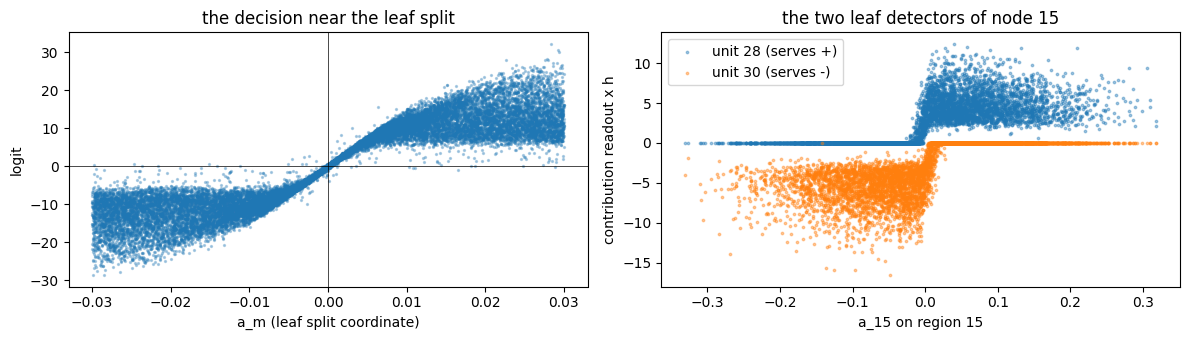

In [6]:
def logit_with(keep):
    h = h2 * keep[None, :]; S_ = h @ W3.T; return np.maximum(S_, 0) @ Wo.ravel()
print("ablations (units of the removed levels silenced, the rest unchanged):")
for name, keep in [("all units", np.ones(60)), ("level-3 units only", (NODE_LEVEL[unode] == 3).astype(float)), ("levels 2-3", (NODE_LEVEL[unode] >= 2).astype(float)), ("levels 1-3", (NODE_LEVEL[unode] >= 1).astype(float)), ("levels 0-2 (no leaf detectors)", (NODE_LEVEL[unode] < 3).astype(float))]:
    lg = logit_with(keep); print(f"  {name:32s}: test error {((lg >= 0) != (y > 0)).mean():.4f}, log loss {np.mean(np.log1p(np.exp(-y * lg))):.4f}, logit rms {np.sqrt((lg ** 2).mean()):.1f}")
# third layer
print(f"\nthird layer: S = sum over s=+ units of W3[0, u] h_u  with W3[0] on s=+ units in [{W3[0][ups > 0].min():.2f}, {W3[0][ups > 0].max():.2f}] and on s=- units in [{W3[0][ups < 0].min():.2f}, {W3[0][ups < 0].max():.2f}]; Sc likewise with W3[1] on s=- units in [{W3[1][ups < 0].min():.2f}, {W3[1][ups < 0].max():.2f}] and on s=+ units in [{W3[1][ups > 0].min():.2f}, {W3[1][ups > 0].max():.2f}]")
print(f"S <= 0 on {(S[:, 0] <= 0).mean():.3f} of points, Sc <= 0 on {(S[:, 1] <= 0).mean():.3f}; corr(S, -Sc) = {np.corrcoef(S[:, 0], -S[:, 1])[0, 1]:.3f}; logit = {Wo[0, 0]:.1f} relu(S) {Wo[0, 1]:+.1f} relu(Sc)")
lin = h2 @ readout; print(f"sign(logit) agrees with the linear readout sum_u readout_u h_u on {(np.sign(logit) == np.sign(lin)).mean():.4f} of points; W3 magnitude by unit level: " + ", ".join(f"L{l}: {np.mean([abs(W3[0 if ups[u] > 0 else 1, u]) for u in range(60) if NODE_LEVEL[unode[u]] == l]):.2f}" for l in range(4)))
# the decision near the boundary
am = A[np.arange(len(A)), m_reached]; err = (logit >= 0) != (y > 0); bins = [0, 0.001, 0.003, 0.01, 0.03, 0.1, 1]
print("\nerror rate by |a_m| (the coordinate of the level-4 split the point reaches):", [(f"{bins[i]}-{bins[i + 1]}", round(float(err[(np.abs(am) >= bins[i]) & (np.abs(am) < bins[i + 1])].mean()), 4)) for i in range(len(bins) - 1)])
print(f"logit: corr with sign(a_m) {np.corrcoef(logit, np.sign(am))[0, 1]:.3f}, with a_m {np.corrcoef(logit, am)[0, 1]:.3f}; mean |logit| {np.abs(logit).mean():.1f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5)); sel = np.abs(am) < 0.03
ax[0].scatter(am[sel][:20000], logit[sel][:20000], s=2, alpha=0.3); ax[0].axhline(0, color="k", lw=0.5); ax[0].axvline(0, color="k", lw=0.5); ax[0].set_xlabel("a_m (leaf split coordinate)"); ax[0].set_ylabel("logit"); ax[0].set_title("the decision near the leaf split")
u_plus = [u for u in lvl3 if t3.set_index("unit").loc[u, "region m"] == 15 and t3.set_index("unit").loc[u, "label served"] == 1][0]; u_minus = [u for u in lvl3 if t3.set_index("unit").loc[u, "region m"] == 15 and t3.set_index("unit").loc[u, "label served"] == -1][0]
r15 = m_reached == 15; ax[1].scatter(A[r15, 15], contrib[r15, u_plus], s=3, alpha=0.4, label=f"unit {u_plus} (serves +)"); ax[1].scatter(A[r15, 15], contrib[r15, u_minus], s=3, alpha=0.4, label=f"unit {u_minus} (serves -)")
ax[1].set_xlabel("a_15 on region 15"); ax[1].set_ylabel("contribution readout x h"); ax[1].legend(); ax[1].set_title("the two leaf detectors of node 15"); plt.tight_layout(); plt.show()

**Findings.**
- **The leaf detectors decide.** Silencing everything but the 32 level-3 units leaves a working classifier (test error 1.1%, logit rms
  5.5); silencing the leaf detectors instead leaves 26% error. The lower levels add margin: with levels 2-3 the error is 0.22%, with
  levels 1-3 0.20%, with everything 0.14%, and the logit rms goes from 5.5 to 14. Their contribution is mostly a positive-or-negative
  offset that follows the leaf detectors' sign (correlation of the level-2 total with the label 0.53) and a near-constant part that the
  third layer absorbs.
- **The third layer is two opposed evidence sums, each gated.** Each third-layer neuron reads its own sign's units positively (0.65
  to 3.7) and the other sign's units negatively (down to -5), so S is the positive evidence minus the negative one and Sc the reverse;
  they are anti-correlated (correlation of S with -Sc is 0.79) but not mirror images. Each gate closes on 8% of the points, where
  that sign's evidence loses, and the gated logit `22.5 relu(S) - 22.6 relu(Sc)` differs in sign from the plain linear sum of the units'
  contributions on 12% of points, so the third layer is not merely a linear readout here. Its weights grow with the unit's level (0.8 /
  0.9 / 2.3 / 3.3), the third layer's own way of weighting the leaf detectors above the coarse units.
- **The decision near the leaf split is linear in a_m.** On region m the two detectors for m output their backgrounds, and the one
  serving the wrong sign is cut by its cue veto at the rate of 4 units per unit of |a_m|, so the logit is `readout x (b_+ - b_-) +
  (readout x cue veto) a_m` near a_m = 0: a line of slope about 300 crossing zero close to a_m = 0 (left panel). Errors live only where
  |a_m| < 0.001 (10% error there, 0.4% for |a_m| in 0.001-0.003, under 0.1% beyond), which is the 0.13% test error. The network
  therefore implements the tree as a sum over the 32 (leaf, sign) cells of `readout_(m,s) b(x) 1[x reaches m, sign(a_m) = s]`, with
  the cell membership computed by vetoes on the wrong side of every split on the path and the sign by a veto on the wrong cue.
